# Catalogs by design: interloper fractions

This notebook builds catalogs whose interlopers are chosen in advance: the share of the catalog each kind of interloper
makes. It follows the two steps of notebooks 01 and 02 with two new pieces. The oxygen lines are rescaled as in
notebook 01 (`RESCALING`, first cell).

1. **`base.make_proposal(z_range, line, flux_limit, interloper_fraction=...)`** takes the total interloper fraction
   expected in the catalog. Besides the single-line fractions and the potential interlopers, the proposal scans the
   **secondary limit**, the threshold above which a galaxy's other lines are detected. A higher secondary limit leaves
   more galaxies with a single line, and so more potential interlopers. For every secondary limit, the proposal gives
   how much of the catalog each kind of interloper can make (if every one were taken), the total, and from which
   secondary limit the expected total is possible. The scan costs nothing extra: every sensitivity model puts the
   secondary limit at a fixed fraction of the primary one, so one number per galaxy decides its lines at every
   secondary limit.
2. **`proposal.make_catalog(fractions=..., secondary_flux_limit=..., out_dir=...)`** takes the table of interloper
   fractions, e.g. `{"Ha": {"OIII_5007": 0.005, "SIII_9532": 0.005}}`. The [O III] λ5007 and [S III] λ9532 galaxies
   taken for Hα each make 0.5 % of the catalog (of the Hα sample for `line="Ha"`; of every galaxy for `line="all"`).
   With `N` the sample, `n` the potential interlopers of a pair at the chosen secondary limit and `F` the sum of the
   fractions, the catalog holds `N / (1 − F)` galaxies. A single line of the pair, where it would get a redshift inside
   the range, is taken for Hα with the probability `P = f N / ((1 − F) n)`. Every other galaxy keeps its line, so no
   galaxy of the sample is lost.

The proposal here gives no secondary limit. With an expected interloper fraction, its own tables are then those of a
single tier (the secondary limit at the primary one), and step 2 chooses the secondary limit. Without
`interloper_fraction` it would be a proposal for single-line clean catalogs (notebook 05).

Run it on a CPU node, from the package directory: `sbatch scripts/run_notebook.sh notebooks/04_catalog_by_design.ipynb`
(about 3 minutes). The catalogs go to `$PSCRATCH/RomanMocks/examples/`.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")      # romanmock imports diffsky, which imports JAX; keep it off the GPU

import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from romanmock import BaseCatalog, Catalog, LineFactors, Proposal, plotting
from romanmock.plotting import OUTCOME_COLORS, TEXT_PRIMARY, feature_color, feature_label

plotting.use_style()
BASE = "/global/cfs/cdirs/m4943/Simulations/RomanMocks/sdss_feniks_hizels_261013_10_14_2026/base"
OUT = Path(os.environ["PSCRATCH"]) / "RomanMocks" / "examples"      # scratch: purged after 8 weeks without access
N_WORKERS = 64 if "SLURM_JOB_ID" in os.environ else None           # a whole CPU node; None: what a login node allows
base = BaseCatalog(BASE)
print(base)

# The rescaling of the oxygen lines (introduction of notebook 01): [O III] gets a scatter of 0.19 dex, and [O II] is
# brightened by 0.25 dex with a scatter of 0.11 dex. One deviate per galaxy; the other lines keep their raw fluxes.
RESCALING = LineFactors(log_offsets={"OII_3727": 0.25}, scatter={"OIII_5007": 0.19, "OIII_4959": 0.19, "OII_3727": 0.11})
print(RESCALING.describe(base.line_set))


<BaseCatalog /global/cfs/cdirs/m4943/Simulations/RomanMocks/sdss_feniks_hizels_261013_10_14_2026/base: 403,068,868 galaxies in 67 slices, 0.00 < z < 4.00; flux limit 1.00e-18 erg/s/cm2 in 10000-19300 A; lines ['Ha', 'Hb', 'OIII_5007', 'OIII_4959', 'OII_3727', 'SIII_9532', 'SIII_9069', 'OIII_4363', 'SIII_6312', 'PaA']>
line_factors rescaling: OIII_5007 x1.000 ±0.19 dex, OIII_4959 x1.000 ±0.19 dex, OII_3727 x1.778 ±0.11 dex


## Step 1: the proposal and the scan of the secondary limit

The inputs are Hα at 1.0 < z < 1.2, a primary flux limit of 1.5 × 10⁻¹⁶ erg s⁻¹ cm⁻², and 1 % of interlopers expected in
all. The summary ends with **Interlopers against the secondary limit**. Its rows are the kinds of interloper and the
total; its columns are secondary limits, from where any interloper becomes possible up to the primary limit.
Each value is the share of the catalog if every potential interloper were taken, the most
any identification gives. `proposal.plot_secondary()` draws it: the dashed line is the expected total, and the dot the
lowest secondary limit that allows it.

[romanmock] line = "Ha": which galaxies the catalog holds
  ▶ "Ha"         the galaxies in which Hα is identified, with z = λ_obs / 6564.7 Å − 1 inside
                 z_range: Hα detected, alone or with other lines, or a single line taken for Hα (an
                 interloper)
    "OIII_5007"  the same for [O III] λ5007, z = λ_obs / 5008.3 Å − 1; a galaxy with both lines is
                 in both catalogs
    "all"        every galaxy with a redshift inside z_range, whichever line gave it
    or           "Hb", "OIII_4959", "OII_3727", "SIII_9532", "SIII_9069", "OIII_4363", "SIII_6312",
                 "PaA"


[romanmock] proposal: scanning 32 of 67 slices with 64 worker(s) …

 done in 26 s



━━ Proposal · Hα at 1.0 ≤ z ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds    F > 1.50e-16
  line fluxes   rescaled (line_factors)
  doublet       OIII_4959 a line of its own where the doublet is resolved for the galaxy's size
                (dip ≥ 20 %), added to OIII_5007 where blended; merged in 59 % of the detected
                galaxies with both lines in the bandpass
  sample        12,617,496 galaxies with Hα detected at 1.0 ≤ z < 1.2 (4,894 per deg²)
  interlopers   1.00 % of the catalog expected in all

── Single-line galaxies inside the range ───────────────────────────────────────────────────────────
  line        galaxies  of all¹  of single¹
  ─────────  ─────────  ───────  ──────────
  all        6,001,764  44.13 %
  Ha         5,019,723  36.91 %     83.64 %
  OIII_5007    981,805   7.22 %     16.36 %
  ¹ of the 13,599,636 galaxies detected at 1.0 ≤ z < 1.2 (true redshift), and of the 6,001,764
    single-line ones among them
  m

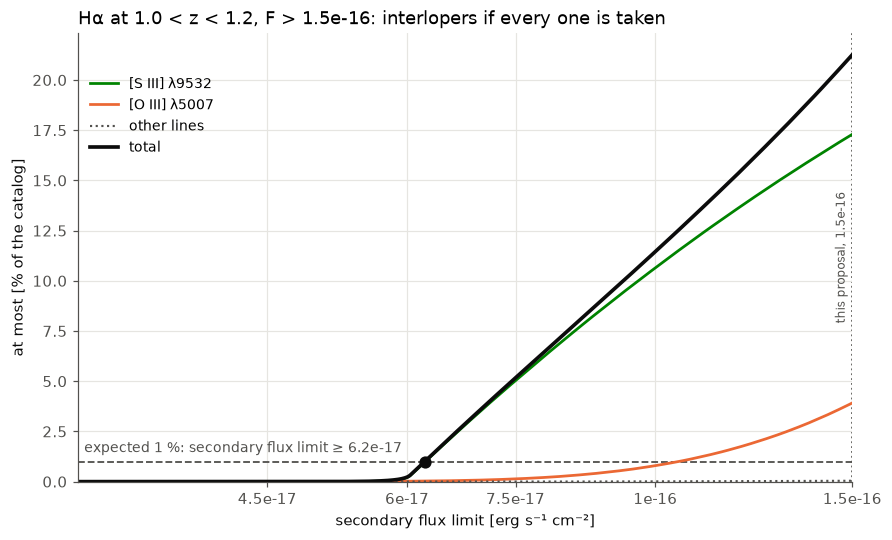

In [2]:
proposal = base.make_proposal((1.0, 1.2), line="Ha", flux_limit=1.5e-16, interloper_fraction=0.01, rescaling=RESCALING,
                              n_workers=N_WORKERS)
proposal.plot_secondary()
plt.show()


With a single tier the sample is the 12.62 M galaxies with Hα above the primary limit (4,894 per deg²). The scan
shows where the interlopers can come from:

* **Almost no [S III] λ9532 galaxy is single-line below a secondary flux limit of 5.5 × 10⁻¹⁷** (fewer than 1,000,
  and none below 4.5 × 10⁻¹⁷). The mock's λ9532/λ9069 ratio is nearly fixed at 2.5, so λ9069 stays above a lower
  secondary limit. At 6 × 10⁻¹⁷ they could make 0.21 % of the catalog.
* **Between 6 and 8 × 10⁻¹⁷ the possible interlopers jump from 0.23 % to 6.6 % of the catalog**, nearly all [S III]. At
  the primary limit they could be 21 % of it.
* **[O III] interlopers are scarce**: none below 3.1 × 10⁻¹⁷, at most 0.14 % of the catalog at 7.5 × 10⁻¹⁷, 0.80 % at
  10⁻¹⁶ and 3.9 % at the primary limit.
* **The expected 1 % needs a secondary flux limit of at least 6.2 × 10⁻¹⁷**: the dot in the figure.

## Step 2: the design and the catalog

The table is 0.5 % of [O III] λ5007 interlopers and 0.5 % of [S III] λ9532 ones, at a secondary flux limit of
1.0 × 10⁻¹⁶ (two thirds of the primary limit). At half the primary limit, 7.5 × 10⁻¹⁷, the mock has too few single
[O III] lines for 0.5 %: the scan gives at most 0.14 %. `proposal.design` says what the table takes without making the
catalog: the potential interlopers of each pair, and the probability P that such a single line is taken for Hα.

In [3]:
table = {"Ha": {"OIII_5007": 0.005, "SIII_9532": 0.005}}
d = proposal.design(table, secondary_flux_limit=1e-16)
for r in d["pairs"]:
    print(f"{r['line']:>10s} as {r['as']}: {100 * r['fraction']:.2f} % of the catalog, {r['n_potential']:,.0f} potential, "
          f"P = {r['p']:.4f}, {r['n_expected']:,.0f} expected")
print(f"catalog: {d['n_sample']:,.0f} galaxies in the sample -> {d['n_catalog']:,.0f} with the interlopers")


 OIII_5007 as Ha: 0.50 % of the catalog, 120,836 potential, P = 0.5616, 67,860 expected
 SIII_9532 as Ha: 0.50 % of the catalog, 1,615,414 potential, P = 0.0420, 67,860 expected
catalog: 13,436,324 galaxies in the sample -> 13,572,044 with the interlopers


A table that needs more interlopers than there are single lines is refused, with the lowest secondary limit that
meets it:

In [4]:
try:
    proposal.design({"Ha": {"OIII_5007": 0.02}}, secondary_flux_limit=1e-16)
except ValueError as err:
    print("ValueError:", err)


ValueError: too few single lines at a secondary flux limit of 1e-16: OIII_5007 -> Ha 2 % needs 274,211 of the 120,836 there are; the table can be met with a secondary flux limit of at least 1.2e-16, or ask for smaller fractions


`make_catalog(fractions=...)` prints the design, makes the catalog, and prints its summary, its line report and the
fractions asked and made. The summary file keeps the design and the fractions made.

In [5]:
cat = proposal.make_catalog(fractions=table, secondary_flux_limit=1e-16, out_dir=OUT / "Ha_z1p0_1p2_design",
                            n_workers=N_WORKERS)


━━ Interlopers by design · Hα at 1.0 ≤ z ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds   F > 1.50e-16 (other lines > 1.00e-16)
  sample       13,436,324 galaxies with Hα detected inside the range
  catalog      13,572,044 galaxies expected, 1.00 % of them interlopers

  line       fraction¹  potential²      P³  expected
  ─────────  ─────────  ──────────  ──────  ────────
  OIII_5007    0.500 %     120,836  0.5616    67,860
  SIII_9532    0.500 %   1,615,414  0.0420    67,860
  ¹ asked: the share of the catalog
  ² single lines where Hα would be inside the range, at a secondary flux limit of 1e-16
  ³ the probability that such a single line is taken for Hα; elsewhere, and for the lines not
    listed, the identification is correct



[romanmock] catalog: scanning 67 slices with 64 worker(s) …

 done in 25 s



━━ Catalog · Hα · 1.0 ≤ z_assigned ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds       F > 1.50e-16 (other lines > 1.00e-16)
  line fluxes      rescaled (line_factors); [O III] doublet per_galaxy
  identification   by design, shares of the catalog: OIII_5007 → Ha 0.5 % (P 0.562), SIII_9532 → Ha
                   0.5 % (P 0.042)
  sky area         2578.31 deg² (estimated from the sky patches of the mock)
  base catalog     91,617,494 of its 403,068,868 galaxies detected
  columns          gal_id, ra, dec, redshift_true, redshift_rsd, redshift_assigned, id_outcome,
                   line_true, line_assigned, n_det

  galaxies                                       number     share
  ─────────────────────────────────────────  ──────────  ────────
  multi-line                                 11,259,861   82.97 %
  single line, correct redshift               2,176,472   16.04 %
  single line taken for another: interloper     135,304    1.00 %
  all        


── Interlopers by design: asked and made ───────────────────────────────────────────────────────────
  line         asked     made  interlopers  expected
  ─────────  ───────  ───────  ───────────  ────────
  OIII_5007  0.500 %  0.499 %       67,687    67,860
  SIII_9532  0.500 %  0.498 %       67,617    67,860
  13,571,637 galaxies in the catalog (13,572,044 expected); each pair's interlopers are drawn one by
  one, so their number scatters by about its square root



[romanmock] wrote to /pscratch/sd/w/willlake/RomanMocks/examples/Ha_z1p0_1p2_design/
            Ha_z1p0_1p2.hdf5, Ha_z1p0_1p2_summary.json, Ha_z1p0_1p2_proposal.npz


At 1.0 × 10⁻¹⁶ there are 120,836 potential [O III] interlopers and 1,615,414 [S III] λ9532 ones:

* **The design** takes [O III] for Hα with P = 0.562 and [S III] with P = 0.042, about 67,860 of each. The catalog
  grows from the 13.44 M galaxies of the sample to 13.57 M.
* **Made:** 0.499 % [O III] (67,687) and 0.498 % [S III] (67,617), each within its binomial scatter (±173 and ±255).
* **Nothing else changes.** The 13,436,333 galaxies with a correct redshift are the sample. The design's 13,436,324 comes
  from the scan, interpolated between its edges.
* **2 % of [O III] would need 274,211** of the 120,836 single lines there are. It is refused, and the lowest secondary
  limit that meets it is 1.2 × 10⁻¹⁶.

In proportion to their numbers, 1 % is 0.97 % [S III] and 0.03 % [O III] at 7.5 × 10⁻¹⁷, and 0.93 % and 0.07 % at
10⁻¹⁶.

## A total shared in proportion

`proposal.fraction_template(total, secondary_flux_limit=...)` shares an expected total among the potential interlopers in
proportion to their numbers at that secondary limit, so every one of them is taken with the same probability. The table
can be edited before `make_catalog`.

In [6]:
for second in (7.5e-17, 1e-16):
    print(f"secondary {second:.2g}:", proposal.fraction_template(0.01, secondary_flux_limit=second))


secondary 7.5e-17: {'Ha': {'SIII_9532': 0.009734, 'OIII_5007': 0.0002657}}
secondary 1e-16: {'Ha': {'SIII_9532': 0.009304, 'OIII_5007': 0.000696}}


## S/N thresholds

The same scan with S/N ≥ 5 for the primary line, for the size of each galaxy, with 3 % of interlopers expected. The
columns are then secondary S/N values, and `make_catalog(fractions=..., secondary_snr=..., ...)` would make the
catalog.

[romanmock] line = "Ha": which galaxies the catalog holds
  ▶ "Ha"         the galaxies in which Hα is identified, with z = λ_obs / 6564.7 Å − 1 inside
                 z_range: Hα detected, alone or with other lines, or a single line taken for Hα (an
                 interloper)
    "OIII_5007"  the same for [O III] λ5007, z = λ_obs / 5008.3 Å − 1; a galaxy with both lines is
                 in both catalogs
    "all"        every galaxy with a redshift inside z_range, whichever line gave it
    or           "Hb", "OIII_4959", "OII_3727", "SIII_9532", "SIII_9069", "OIII_4363", "SIII_6312",
                 "PaA"


[romanmock] proposal: scanning 32 of 67 slices with 64 worker(s) …

 done in 36 s



━━ Proposal · Hα at 1.0 ≤ z ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds    S/N ≥ 5, size r50_disk_2d [kpc] / D_A(redshift_true), 1 h, 2 x min zodi
  line fluxes   rescaled (line_factors)
  doublet       OIII_4959 a line of its own where the doublet is resolved for the galaxy's size
                (dip ≥ 20 %), added to OIII_5007 where blended; merged in 33 % of the detected
                galaxies with both lines in the bandpass
  sample        16,449,077 galaxies with Hα detected at 1.0 ≤ z < 1.2 (6,380 per deg²)
  interlopers   3.00 % of the catalog expected in all

── Single-line galaxies inside the range ───────────────────────────────────────────────────────────
  line         galaxies  of all¹  of single¹
  ─────────  ──────────  ───────  ──────────
  all        12,005,256  72.78 %
  Ha         11,958,472  72.49 %     99.61 %
  OIII_5007      46,777   0.28 %      0.39 %
  ¹ of the 16,495,861 galaxies detected at 1.0 ≤ z < 1.2 (true red

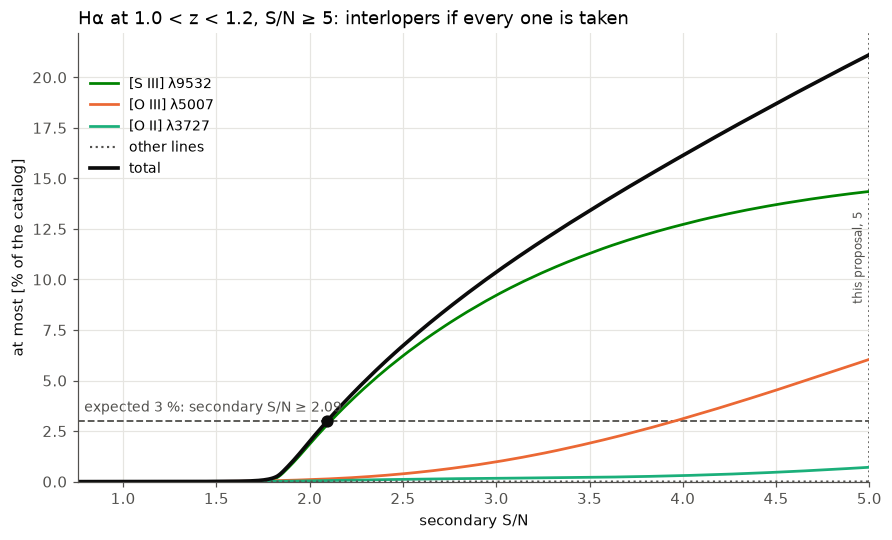

In [7]:
proposal_snr = base.make_proposal((1.0, 1.2), line="Ha", snr=5, size="r50_disk_2d", interloper_fraction=0.03,
                                  rescaling=RESCALING, n_workers=N_WORKERS)
proposal_snr.plot_secondary()
plt.show()


With S/N ≥ 5 and a single tier, the sample is 16.45 M galaxies (6,380 per deg²):

* almost no line is single below a secondary S/N of 1.5 (0.01 % of the catalog there); from 2 on, [S III] λ9532
  dominates;
* at most 2.0 % of the catalog at secondary S/N 2, 6.7 % at 2.5 and 21 % at 5, the primary S/N;
* the expected 3 % needs a secondary S/N of at least 2.09.

## Every galaxy at 1.6 < z < 2.0

For `line="all"` a potential interloper is a pair, a line taken for another, and the fractions are shares of the whole
catalog. Here the expected 3 % is shared in proportion at a secondary limit of 7.5 × 10⁻¹⁷.

[romanmock] line = "all": which galaxies the catalog holds
    "Ha"         the galaxies in which Hα is identified, with z = λ_obs / 6564.7 Å − 1 inside
                 z_range: Hα detected, alone or with other lines, or a single line taken for Hα (an
                 interloper)
    "OIII_5007"  the same for [O III] λ5007, z = λ_obs / 5008.3 Å − 1; a galaxy with both lines is
                 in both catalogs
  ▶ "all"        every galaxy with a redshift inside z_range, whichever line gave it
    or           "Hb", "OIII_4959", "OII_3727", "SIII_9532", "SIII_9069", "OIII_4363", "SIII_6312",
                 "PaA"


[romanmock] proposal: scanning 67 of 67 slices with 64 worker(s) …

 done in 33 s



━━ Proposal · every galaxy at 1.6 ≤ z ≤ 2.0 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds    F > 1.50e-16
  line fluxes   rescaled (line_factors)
  doublet       OIII_4959 a line of its own where the doublet is resolved for the galaxy's size
                (dip ≥ 20 %), added to OIII_5007 where blended; merged in 59 % of the detected
                galaxies with both lines in the bandpass
  sample        9,664,858 detected galaxies at 1.6 ≤ z < 2.0 (3,749 per deg²)
  interlopers   3.00 % of the catalog expected in all

── Single-line galaxies inside the range ───────────────────────────────────────────────────────────
  line        galaxies  of all¹  of single¹
  ─────────  ─────────  ───────  ──────────
  all        5,467,003  56.57 %
  Ha         4,209,765  43.56 %     77.00 %
  OIII_5007  1,256,895  13.00 %     22.99 %
  ¹ of the 9,664,858 galaxies detected at 1.6 ≤ z < 2.0 (true redshift), and of the 5,467,003
    single-line ones among them
  minor (fewe

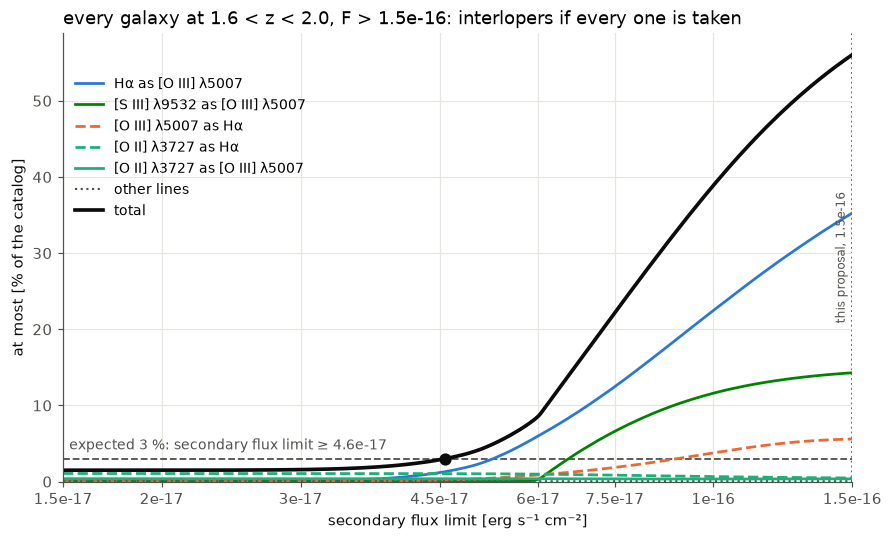

{
 "OIII_5007": {
  "Ha": 0.0169,
  "SIII_9532": 0.008952,
  "OII_3727": 0.0004801
 },
 "Ha": {
  "OIII_5007": 0.002526,
  "OII_3727": 0.001144
 }
}
━━ Interlopers by design · every galaxy at 1.6 ≤ z ≤ 2.0 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds   F > 1.50e-16 (other lines > 7.50e-17)
  sample       9,664,858 detected galaxies inside the range
  catalog      9,963,793 galaxies expected, 3.00 % of them interlopers

  line       taken for  fraction¹  potential²      P³  expected
  ─────────  ─────────  ─────────  ──────────  ──────  ────────
  Ha         OIII_5007    1.690 %   1,547,773  0.1088   168,388
  SIII_9532  OIII_5007    0.895 %     819,948  0.1088    89,196
  OII_3727   OIII_5007    0.048 %      43,976  0.1088     4,784
  OIII_5007  Ha           0.253 %     231,417  0.1088    25,169
  OII_3727   Ha           0.114 %     104,795  0.1088    11,399
  ¹ asked: the share of the catalog
  ² single lines where that line would be inside the range, at a secondary flux l

[romanmock] catalog: scanning 67 slices with 64 worker(s) …

 done in 25 s



━━ Catalog · every galaxy · 1.6 ≤ z_assigned ≤ 2.0 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds       F > 1.50e-16 (other lines > 7.50e-17)
  line fluxes      rescaled (line_factors); [O III] doublet per_galaxy
  identification   by design, shares of the catalog: Ha → OIII_5007 1.69 % (P 0.109), SIII_9532 →
                   OIII_5007 0.895 % (P 0.109), OII_3727 → OIII_5007 0.048 % (P 0.109), OIII_5007 →
                   Ha 0.253 % (P 0.109), OII_3727 → Ha 0.114 % (P 0.109)
  sky area         2578.31 deg² (estimated from the sky patches of the mock)
  base catalog     91,617,494 of its 403,068,868 galaxies detected
  columns          gal_id, ra, dec, redshift_true, redshift_rsd, redshift_assigned, id_outcome,
                   line_true, line_assigned, n_det

  galaxies                                      number     share
  ─────────────────────────────────────────  ─────────  ────────
  multi-line                                 8,547,220   85.79 %
  single lin


── Interlopers by design: asked and made ───────────────────────────────────────────────────────────
  line       taken for    asked     made  interlopers  expected
  ─────────  ─────────  ───────  ───────  ───────────  ────────
  Ha         OIII_5007  1.690 %  1.687 %      168,100   168,388
  SIII_9532  OIII_5007  0.895 %  0.892 %       88,855    89,196
  OII_3727   OIII_5007  0.048 %  0.049 %        4,838     4,784
  OIII_5007  Ha         0.253 %  0.253 %       25,183    25,169
  OII_3727   Ha         0.114 %  0.117 %       11,642    11,399
  9,963,476 galaxies in the catalog (9,963,793 expected); each pair's interlopers are drawn one by
  one, so their number scatters by about its square root



[romanmock] wrote to /pscratch/sd/w/willlake/RomanMocks/examples/all_z1p6_2p0_design/
            all_z1p6_2p0.hdf5, all_z1p6_2p0_summary.json, all_z1p6_2p0_proposal.npz


In [8]:
proposal_all = base.make_proposal((1.6, 2.0), line="all", flux_limit=1.5e-16, interloper_fraction=0.03, rescaling=RESCALING,
                                  n_workers=N_WORKERS)
proposal_all.plot_secondary()
plt.show()
table_all = proposal_all.fraction_template(0.03, secondary_flux_limit=7.5e-17)
print(json.dumps(table_all, indent=1))
cat_all = proposal_all.make_catalog(fractions=table_all, secondary_flux_limit=7.5e-17, out_dir=OUT / "all_z1p6_2p0_design",
                                    n_workers=N_WORKERS)


For every galaxy at 1.6 < z < 2.0, 9.66 M detected galaxies:

* **Some interlopers are possible at every secondary limit.** Above z ≈ 2.85 [O II] is the only line in the
  bandpass, and those single lines alone could make 1.5 % of the catalog.
* **The expected 3 % is possible from 4.6 × 10⁻¹⁷.**
* **Shared in proportion at 7.5 × 10⁻¹⁷:** Hα → [O III] 1.69 %, [S III] λ9532 → [O III] 0.90 %, [O III] → Hα
  0.25 %, [O II] → Hα 0.11 % and [O II] → [O III] 0.05 %.
* **Made:** 2.997 % (298,618 interlopers). Four pairs are within 1.3 times their binomial scatter; [O II] → Hα is 2 %
  above its expectation (11,642 for 11,399, 2.4 times its scatter). The 9,664,858 galaxies with a correct redshift
  are exactly the sample: none is lost, because a single line is taken for another only where it then lands inside the
  range.

## What is in the catalogs

These are the parts of the two catalogs (notebook 01 explains `id_outcome`, `line_true` and `line_assigned`), with one
entry per kind of interloper, and their dN/dz against the assigned redshift.

(a) Hα, 0.5 % [O III] + 0.5 % [S III]: 13,571,637 galaxies
  all                       13,571,637   100.000 %


  multi_line                11,259,861    82.966 %


  single_correct             2,176,472    16.037 %


  galaxies                  13,436,333    99.003 %
  interlopers                  135,304     0.997 %
  OIII_5007_as_Ha               67,687     0.499 %
  SIII_9532_as_Ha               67,617     0.498 %


(b) every galaxy, 3 % in proportion: 9,963,476 galaxies
  all                        9,963,476   100.000 %


  multi_line                 8,547,220    85.786 %


  single_correct             1,117,638    11.217 %


  galaxies                   9,664,858    97.003 %
  interlopers                  298,618     2.997 %
  Ha_as_OIII_5007              168,100     1.687 %
  SIII_9532_as_OIII_5007        88,855     0.892 %
  OIII_5007_as_Ha               25,183     0.253 %
  OII_3727_as_Ha                11,642     0.117 %
  OII_3727_as_OIII_5007          4,838     0.049 %


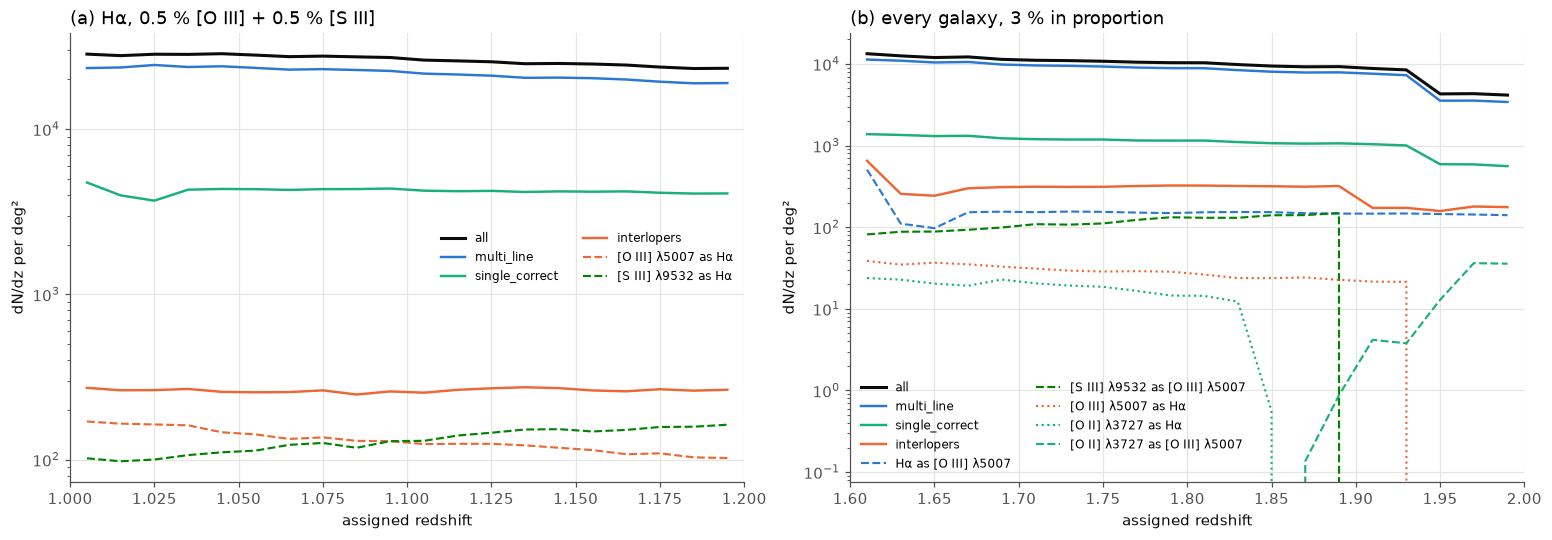

In [9]:
COLORS = {"all": TEXT_PRIMARY, "multi_line": OUTCOME_COLORS["MULTI_LINE"], "single_correct": OUTCOME_COLORS["SINGLE_CORRECT"],
          "interlopers": OUTCOME_COLORS["SINGLE_MISID"]}


def show_components(cat, name, ax, edges, min_count=100):
    """Print the components of a catalog and draw dN/dz of each against the assigned redshift. A kind of interloper
    has the colour of its true line and one line style per line it is taken for; those with fewer than min_count
    galaxies are listed only."""
    comp = cat.components()
    zc = 0.5 * (edges[1:] + edges[:-1])
    styles = {}
    print(f"{name}: {len(cat):,} galaxies")
    for which, n in comp.items():
        print(f"  {which:<24s}{n:>12,}{100 * n / comp['all']:>10.3f} %")
        if which == "galaxies" or n < min_count:
            continue
        if which in COLORS:
            ax.plot(zc, cat.subset(which).dndz(edges), color=COLORS[which], lw=2.0 if which == "all" else 1.6, label=which)
        else:
            true, taken = which.split("_as_")
            ls = styles.setdefault(taken, ("--", ":", "-.")[len(styles) % 3])
            ax.plot(zc, cat.subset(which).dndz(edges), color=feature_color(true), ls=ls, lw=1.4,
                    label=f"{feature_label(true)} as {feature_label(taken)}")
    ax.set_yscale("log")
    ax.set_xlim(edges[0], edges[-1])
    ax.set_xlabel("assigned redshift")
    ax.set_ylabel("dN/dz per deg²")
    ax.set_title(name, loc="left")
    ax.legend(fontsize=8, ncol=2)


fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True)
show_components(cat, "(a) Hα, 0.5 % [O III] + 0.5 % [S III]", axes[0], np.linspace(1.0, 1.2, 21))
show_components(cat_all, "(b) every galaxy, 3 % in proportion", axes[1], np.linspace(1.6, 2.0, 21))
plt.show()


## Summary

* **`make_proposal(..., interloper_fraction=...)`** scans the secondary limit. It shows the most each kind of
  interloper can make of the catalog at every secondary limit, and from which one the expected total is possible:
  6.2 × 10⁻¹⁷ for 1 % in the Hα catalog at 1.0–1.2, and 4.6 × 10⁻¹⁷ for 3 % of every galaxy at 1.6–2.0.
* **`make_catalog(fractions=..., secondary_flux_limit=...)`** makes the interlopers asked for: 0.499 % and 0.498 % for
  0.5 % each, 2.997 % for 3 %. The sample is untouched. `design` says what a table takes, and refuses one that the
  single lines cannot meet. `fraction_template` shares a total in proportion.
* Single [O III] lines that can be taken for Hα are scarce at 1.0 < z < 1.2: a catalog with 0.5 % of them needs a
  secondary flux limit of at least 9 × 10⁻¹⁷.
* The notebook ran in 2.4 minutes on a CPU node.